# [01-2] 전처리 · 머신러닝 모델 · 성능평가 — EOL 최종검사 불량 선별

**K-뉴딜 아카데미 스마트팩토리 캡스톤 · 공통 미니 프로젝트 (1~2회차 · 4개 팀 동일 데이터)**

---

## 이 노트북의 학습목표

1. 1편에서 찾은 문제를 **정제 규칙(코드)** 으로 고정한다.
2. **데이터 누출을 막는 특성 선정**과 **train/test 분리**를 한다.
3. **결측 대치 · 스케일링 · 원핫인코딩**을 파이프라인으로 묶는다.
4. **로지스틱 회귀 · 의사결정나무 · 랜덤포레스트** 3가지 모델을 학습한다.
5. **혼동행렬 · Precision · Recall · F1 · ROC-AUC**로 모델을 비교하고,
   **임계값을 조정**해 현장 운영조건에 맞춘다.

## 머신러닝이란 무엇인가 (3분 요약)

머신러닝은 마법이 아니라 **"과거 데이터에서 패턴을 찾아 규칙을 자동으로 만드는 것"** 입니다.

| 방식 | 규칙을 누가 만드나 | 예 |
|---|---|---|
| 전통적 방식 | **사람**이 경험으로 정한다 | "토크가 27 미만이면 추가검사" |
| 머신러닝 | **데이터**에서 자동으로 찾는다 | 여러 변수를 조합한 복잡한 경계를 학습 |

머신러닝이 사람보다 나은 점은 **여러 변수를 동시에 고려**할 수 있다는 것입니다.
사람은 변수 2~3개까지는 표로 비교할 수 있지만, 15개 변수의 조합은 다루기 어렵습니다.

반대로 머신러닝이 못 하는 것도 분명합니다.
- **원인을 알려 주지 않습니다.** (상관만 학습합니다)
- **데이터에 없는 상황은 모릅니다.** (새로운 고장 유형은 못 잡습니다)
- **데이터가 틀리면 같이 틀립니다.**

### 이 노트북에서 쓰는 것: 지도학습 분류(supervised classification)

- **지도학습**: 정답(label)이 있는 데이터로 학습한다 → 우리는 4.0% (48/1,200) 의 정답을 가지고 있다
- **분류**: 정답이 범주다 (양성/음성) ↔ 회귀는 정답이 숫자다 (예: 리드타임 몇 분)

---

## 0. 이 노트북을 사용하는 방법

이 노트북은 **1편(데이터 탐색)** 을 마친 뒤에 실행합니다. 1편 없이도 실행되지만, 1편의 발견 내용을 알고 보면 훨씬 이해가 빠릅니다.

**실행 방법**

| 하고 싶은 것 | 방법 |
|---|---|
| 셀 하나 실행 | 셀을 클릭하고 `Shift + Enter` |
| 위에서부터 전체 실행 | 메뉴 `런타임 > 모두 실행` |
| 처음부터 다시 | 메뉴 `런타임 > 런타임 초기화 후 모두 실행` |
| 코드 수정 | 셀 안의 숫자/변수명을 바꾸고 다시 `Shift + Enter` |

**학습 태도에 대한 당부**

- 코드를 **외우려 하지 마세요.** 이 교육의 목표는 "코드를 쓰는 사람"이 아니라
  "데이터로 공정을 판단하는 사람"이 되는 것입니다.
- 각 셀의 주석(`#` 으로 시작하는 줄)과 셀 위의 설명을 먼저 읽고, 출력된 **숫자와 그림이
  현장에서 무슨 뜻인지**를 말로 설명해 보세요.
- 셀 아래의 **생각해 볼 질문**은 발표 자료의 재료가 됩니다. 답을 메모해 두세요.
- 에러가 나면 당황하지 말고 **맨 아랫줄(마지막 Error 문장)** 부터 읽으세요. 대부분
  오타, 변수명 불일치, 셀 실행 순서 문제입니다.

> 이 데이터는 **교육용 합성데이터**입니다. 실제 기업의 설비 상태나 품질 수준을 나타내지
> 않습니다. 따라서 여기서 얻은 수치는 "분석 연습의 결과"이며, 현장 결론으로 그대로
> 인용하면 안 됩니다. 반대로 **분석 절차와 해석 방법**은 실제 현장에서 그대로 쓰입니다.

---

## 1. 환경 준비 (라이브러리 / 한글폰트)

분석은 "도구를 꺼내는 일"에서 시작합니다. 파이썬 자체에는 표 계산이나 그래프 기능이
없고, 필요한 기능을 **라이브러리**(기능 묶음)로 불러와서 씁니다. 이 교육에서 쓰는 4가지는
다음과 같습니다.

| 라이브러리 | 별칭 | 역할 | 현장 비유 |
|---|---|---|---|
| `pandas` | `pd` | 표(엑셀 시트) 형태 데이터 처리 | 엑셀 |
| `numpy` | `np` | 숫자 배열·수학 계산 | 공학용 계산기 |
| `matplotlib` | `plt` | 그래프 그리기 | 모눈종이 + 자 |
| `seaborn` | `sns` | 통계 그래프를 짧은 코드로 | 그래프 템플릿 |
| `scikit-learn` | `sklearn` | 머신러닝 모델·전처리·평가 | 분석 엔진 |

`import A as B` 는 "A라는 도구상자를 가져와서 앞으로 B라는 짧은 이름으로 부르겠다"는 뜻입니다.

**한글 폰트**: 그래프 제목·축이름에 한글을 쓰면 기본 설정에서는 □□□ 로 깨집니다.
아래 셀이 Colab/로컬 환경을 자동으로 판별해 한글 폰트를 설정합니다. (한 번만 실행하면 됩니다.)

In [1]:
# =============================================================================
# [1-1] 라이브러리 불러오기 + 한글 폰트 설정
# =============================================================================
import os
import sys
import glob
import warnings

import numpy as np                 # 수치 계산
import pandas as pd                # 표 데이터 처리
import matplotlib as mpl
import matplotlib.pyplot as plt    # 그래프
import seaborn as sns              # 통계 그래프

# scikit-learn: 전처리 / 모델 / 평가
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score)
warnings.filterwarnings("ignore")  # 교육용: 경고 메시지를 숨겨 출력을 깔끔하게 한다

IN_COLAB = "google.colab" in sys.modules   # 지금 Colab에서 실행 중인가?


def setup_korean_font():
    """그래프에 한글이 깨지지 않도록 폰트를 설정한다.

    1) 이미 설치된 한글 폰트가 있으면 그것을 쓴다(로컬 PC/Mac).
    2) 없고 Colab이면 koreanize-matplotlib 패키지를 설치해서 쓴다.
    3) 둘 다 실패하면 영문 폰트를 그대로 쓴다(그래프는 그려지지만 한글이 깨진다).
    """
    from matplotlib import font_manager

    candidates = ["NanumGothic", "NanumBarunGothic", "Malgun Gothic",
                  "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR"]
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in candidates:
        if name in installed:
            mpl.rcParams["font.family"] = name
            mpl.rcParams["axes.unicode_minus"] = False   # 음수 기호(-) 깨짐 방지
            return f"설정 완료: {name}"

    if IN_COLAB:
        try:
            import subprocess
            subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                            "koreanize-matplotlib"], check=True)
            import koreanize_matplotlib  # noqa: F401  (import만 해도 폰트가 적용됨)
            mpl.rcParams["axes.unicode_minus"] = False
            return "설정 완료: koreanize-matplotlib (NanumGothic)"
        except Exception as e:      # 네트워크 차단 등
            return f"한글 폰트 설정 실패({e}) - 그래프의 한글이 깨질 수 있습니다"
    return "한글 폰트를 찾지 못했습니다 - 그래프의 한글이 깨질 수 있습니다"


print(setup_korean_font())

# 그래프 기본 모양 / 표 출력 옵션
sns.set_theme(style="whitegrid", font=mpl.rcParams["font.family"][0] if isinstance(mpl.rcParams["font.family"], list) else mpl.rcParams["font.family"])
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.figsize"] = (9, 5)     # 그래프 기본 크기(가로, 세로 인치)
mpl.rcParams["figure.dpi"] = 110            # 해상도
mpl.rcParams["font.size"] = 11

pd.set_option("display.max_columns", 60)    # 표의 열을 생략하지 않고 보여준다
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("pandas", pd.__version__, "| numpy", np.__version__, "| Colab:", IN_COLAB)

설정 완료: AppleGothic
pandas 2.2.3 | numpy 2.1.3 | Colab: False


---

## 2. 데이터 불러오기

분석할 파일은 **`K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx`** 입니다. 엑셀 파일의 **`MiniCase_Data`** 시트가 원천데이터입니다.

Colab은 내 PC가 아니라 **구글 클라우드의 임시 컴퓨터**에서 돌아갑니다. 따라서 내 PC에 있는
파일을 Colab이 자동으로 볼 수는 없고, 다음 중 하나로 **파일을 올려줘야** 합니다.

| 방법 | 언제 쓰나 | 특징 |
|---|---|---|
| ① 직접 업로드 | 한 번만 쓸 때 | 아래 셀 실행 → 파일 선택. 런타임이 끊기면 다시 올려야 함 |
| ② 구글 드라이브 마운트 | 수업 내내 쓸 때 (권장) | `drive.mount()` 후 내 드라이브 경로를 그대로 사용 |
| ③ 로컬 주피터 | 내 PC에서 실행할 때 | 노트북과 같은 폴더에 두면 자동 인식 |

아래 셀은 ①②③을 **자동으로 판단**합니다. 흔히 쓰는 경로를 먼저 찾아보고, 못 찾으면
업로드 창을 띄웁니다. 드라이브를 쓰려면 아래 주석 2줄의 `#` 을 지우고 실행하세요.

In [2]:
# =============================================================================
# [2-1] 데이터 파일 찾기 → 읽기
# =============================================================================
# (선택) 구글 드라이브를 쓰려면 아래 2줄의 주석을 해제하고 실행하세요.
# from google.colab import drive
# drive.mount('/content/drive')

DATA_FILE = "K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx"      # 찾을 파일명
NAME_HINT = "MiniCase" # 파일명이 조금 달라도 찾기 위한 키워드

SEARCH_DIRS = [
    os.environ.get("KNEWDEAL_DATA_DIR", ""),   # (강사용) 환경변수로 지정한 폴더
    ".", "..", "../..",                        # 노트북 주변 폴더
    "/content",                                # Colab 업로드 기본 위치
    "/content/drive/MyDrive",
    "/content/drive/MyDrive/K뉴딜",
    "/content/drive/MyDrive/Colab Notebooks",
    os.path.expanduser("~/Downloads"),
]


def find_data_file(file_name, name_hint):
    """후보 폴더를 돌면서 파일을 찾는다. 정확한 파일명 → 키워드 부분일치 순으로 탐색."""
    for d in SEARCH_DIRS:
        if not d:
            continue
        p = os.path.join(d, file_name)
        if os.path.exists(p):
            return p
    for d in SEARCH_DIRS:                       # 파일명이 조금 바뀐 경우 대비
        if not d or not os.path.isdir(d):
            continue
        hits = [p for p in glob.glob(os.path.join(d, "*")) if name_hint in os.path.basename(p)]
        if hits:
            return sorted(hits)[0]
    return None


DATA_PATH = find_data_file(DATA_FILE, NAME_HINT)

if DATA_PATH is None and IN_COLAB:
    print("파일을 찾지 못했습니다. 아래 버튼으로 데이터 파일을 업로드하세요.")
    from google.colab import files
    uploaded = files.upload()               # 파일 선택 창이 열린다
    DATA_PATH = list(uploaded.keys())[0]

if DATA_PATH is None:
    raise FileNotFoundError(
        "데이터 파일을 찾을 수 없습니다.\n"
        f" - 찾는 파일: {DATA_FILE}\n"
        " - 해결: (1) Colab 왼쪽 '파일' 탭에 파일을 끌어다 놓거나\n"
        "         (2) 구글 드라이브를 마운트하고 SEARCH_DIRS에 경로를 추가하세요."
    )

print("데이터 경로:", DATA_PATH)
df_raw = pd.read_excel(DATA_PATH, sheet_name="MiniCase_Data")
print("불러온 데이터 크기:", df_raw.shape, "  (행 수, 열 수)")
df_raw.head(3)

데이터 경로: ../../K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx


불러온 데이터 크기: (1200, 20)   (행 수, 열 수)


,record_id,timestamp,shift,line_id,product_model,equipment_id,operator_group,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,inspection_result,defect_type,inspection_time_sec,rework_flag,rework_time_min,final_disposition
0,R00001,2026-07-01 21:00:25,야간,L1,P1,M04,G01,31.460,5.980,51.400,35.200,2.700,0,1.000,합격,NaN,37,N,0,합격
1,R00002,2026-07-02 12:12:10,주간,L2,P2,M04,G02,32.370,5.660,50.600,38.600,2.590,0,0.915,합격,NaN,42,N,0,합격
2,R00003,2026-07-03 10:03:12,주간,L1,P1,M03,G03,30.260,5.680,49.400,39.500,2.270,1,1.044,합격,NaN,46,N,0,합격


In [3]:
# 미니케이스 전용: 토크 결측 복원을 위한 '센서로그' 시트도 함께 읽는다
sensor_log = pd.read_excel(DATA_PATH, sheet_name="센서로그")
print("센서로그:", sensor_log.shape)
sensor_log.head(3)

센서로그: (12, 4)


,record_id,timestamp,torque_nm_restored,근거
0,R00845,2026-07-08 15:37:46,30.650,교육용 합성 센서로그: 정상범위 복원 실습
1,R00268,2026-07-20 09:45:48,31.590,교육용 합성 센서로그: 정상범위 복원 실습
2,R00351,2026-07-10 10:38:06,32.010,교육용 합성 센서로그: 정상범위 복원 실습


---

## 3. 1단계 전처리 — 정제 규칙을 코드로 고정하기

전처리는 두 단계로 나눠서 생각하면 쉽습니다.

| 단계 | 하는 일 | 누가 판단 | 어디에 |
|---|---|---|---|
| **1단계 정제** | 물리적으로 불가능한 값, 구조적 결측, 업무 플래그 | **사람**(도메인 지식) | `clean_data()` 함수 |
| **2단계 변환** | 남은 결측 대치, 스케일링, 원핫인코딩 | 기계(규칙 고정) | `Pipeline` |

**왜 나누는가?** 2단계는 반드시 **학습 데이터에서만 기준을 배워야** 합니다
(예: 중앙값, 평균, 표준편차). 테스트 데이터까지 포함해 중앙값을 구하면
**미래 정보를 미리 본 것**이 되어 성능이 부풀려집니다. 이것도 데이터 누출의 한 형태입니다.
그래서 2단계는 `Pipeline` 안에 넣어 `fit`은 학습 데이터에만 적용합니다.

1단계는 "음수는 불가능하다" 같은 **데이터와 무관한 물리적 사실**이므로 전체에 적용해도
문제가 없습니다.

### 미니케이스 정제 규칙 (1회차 EDA 결과로 확정)

| 항목 | 발견 | 처리 규칙 | 근거 |
|---|---|---|---|
| `torque_nm` 결측 12건 | 모두 합격품. 별도 **센서로그 시트**에 복원값 존재 | **센서로그를 `record_id`로 연결해 복원** | 원본 로그가 있으면 추정보다 항상 우선 |
| `vibration_mm_s` 결측 18건 | 복원자료 없음 | **설비별 중앙값**으로 대치 + `vib_missing` 표시변수 추가 | 설비마다 진동 수준이 다르므로 전체 중앙값보다 정확 |
| `defect_type` 결측 1,152건 | 합격품은 불량유형이 없음 | **그대로 둔다(채우지 않음)** | 구조적 결측. 최빈값 대치는 의미 왜곡 |
| 검사 후 변수 5개 | 누출 위험 | **특성에서 제외** | 예측시점에 존재하지 않음 |

**결측 표시변수(missing indicator)를 추가하는 이유**: "값이 없었다"는 사실 자체가
정보일 수 있습니다(센서 고장, 측정 누락이 특정 설비에 몰려 있는 등). 대치해서
숫자를 채우면 이 정보가 사라지므로, 0/1 변수로 따로 남겨 둡니다.

In [4]:
def clean_data(d, sensor_log=None):
    """미니케이스 1단계 정제: 도메인 지식이 필요한 수정만 수행."""
    d = d.copy()
    report = []

    # ① 토크 결측 → 센서로그 복원값으로 채운다 (원본 로그 우선)
    n_missing = int(d["torque_nm"].isna().sum())
    if sensor_log is not None and n_missing > 0:
        restore = sensor_log.set_index("record_id")["torque_nm_restored"]
        fill = d["record_id"].map(restore)
        d["torque_nm"] = d["torque_nm"].fillna(fill)
        report.append(f"토크 결측 {n_missing}건 → 센서로그 복원값으로 대체 "
                      f"(남은 결측 {int(d['torque_nm'].isna().sum())}건)")

    # ② 진동 결측 → '값이 없었다'는 사실을 표시변수로 남기고, 설비별 중앙값으로 대치
    d["vib_missing"] = d["vibration_mm_s"].isna().astype(int)
    before = int(d["vibration_mm_s"].isna().sum())
    d["vibration_mm_s"] = d["vibration_mm_s"].fillna(
        d.groupby("equipment_id")["vibration_mm_s"].transform("median"))
    report.append(f"진동 결측 {before}건 → 설비별 중앙값 대치 + vib_missing 표시변수 추가")

    # ③ defect_type(불량유형)은 구조적 결측이므로 건드리지 않는다
    report.append("defect_type 결측은 구조적 결측(합격품) → 그대로 유지, 특성에서 제외")

    # ④ 시간 변수는 datetime 형으로 변환 (시간순 정렬·시계열 그래프용)
    d["timestamp"] = pd.to_datetime(d["timestamp"])

    return d, report

In [5]:
# =============================================================================
# [3-2] 정제 실행 + 처리 내역 출력 (재현성을 위해 항상 기록으로 남긴다)
# =============================================================================
df, clean_report = clean_data(df_raw, sensor_log=sensor_log)

print(f"정제 전: {df_raw.shape}  →  정제 후: {df.shape}\n")
print("[처리 내역]")
for i, r in enumerate(clean_report, 1):
    print(f"  {i}. {r}")

print("\n[남은 결측]")
left = df.isna().sum()
left = left[left > 0]
print(left.to_string() if len(left) else "  없음 (또는 의도적으로 남긴 구조적 결측만 존재)")

정제 전: (1200, 20)  →  정제 후: (1200, 21)

[처리 내역]
  1. 토크 결측 12건 → 센서로그 복원값으로 대체 (남은 결측 0건)
  2. 진동 결측 18건 → 설비별 중앙값 대치 + vib_missing 표시변수 추가
  3. defect_type 결측은 구조적 결측(합격품) → 그대로 유지, 특성에서 제외

[남은 결측]
defect_type    1152


---

## 4. 목표변수와 특성(입력변수) 정하기

### 목표변수
목표변수(= 정답, target)는 **`inspection_result`(검사결과)** 입니다.
`불합격`을 **1(양성, positive)**, `합격`을 **0(음성, negative)** 으로 바꿔서 씁니다.

왜 불합격을 1로 둘까요? 머신러닝에서 **양성(1)은 "찾아내고 싶은 드문 사건"** 에 두는 것이
관례입니다. 그래야 Recall(불량 중 몇 %를 찾았나), Precision(경보 중 몇 %가 진짜였나) 같은
지표가 현장 언어와 맞아떨어집니다.

### 데이터 누출을 막는 특성 선정

이 데이터에서는 특성 세트를 하나만 씁니다. **판단 시점(제품이 EOL 검사대에 도착하기 직전 (조립은 끝났고 검사결과는 아직 모르는 시점))에 알 수 있는 변수**만 모았습니다.

> **다시 한 번**: 성능이 높은 모델이 좋은 모델이 아닙니다.
> **판단 시점에 쓸 수 있는 정보만으로 만든 모델**이 현장에서 작동하는 모델입니다.

In [6]:
# =============================================================================
# [4-1] 목표변수와 특성 정의
# =============================================================================
TARGET_COL = "inspection_result"
df["target"] = (df['inspection_result'] == '불합격').astype(int)          # 1 = 불합격(추가확인 대상)

CAT_A = ["shift", "line_id", "product_model", "equipment_id", "operator_group"]      # 범주형 입력
NUM_A = [
    "torque_nm", "pressure_bar", "cycle_time_sec", "temperature_c", "vibration_mm_s",
    "downtime_min", "energy_kwh"
]      # 수치형 입력
LEAK_COLS = [
    "defect_type", "inspection_time_sec", "rework_flag", "rework_time_min",
    "final_disposition", "record_id"
]  # 절대 쓰면 안 되는 결과변수

CAT_A = [c for c in CAT_A if c in df.columns]
NUM_A = [c for c in NUM_A if c in df.columns]

print(f"입력 특성 : 범주형 {len(CAT_A)} + 수치형 {len(NUM_A)} = {len(CAT_A)+len(NUM_A)}개")
print(f"사용 금지 : {LEAK_COLS}")
print(f"\n양성(1) {int(df['target'].sum())}건 / 전체 {len(df)}건 "
      f"= {df['target'].mean()*100:.2f}%")

입력 특성 : 범주형 5 + 수치형 7 = 12개
사용 금지 : ['defect_type', 'inspection_time_sec', 'rework_flag', 'rework_time_min', 'final_disposition', 'record_id']

양성(1) 48건 / 전체 1200건 = 4.00%


---

## 5. 학습용 / 평가용 데이터 분리 (train / test split)

### 왜 나누는가

모델을 **학습에 쓴 데이터로 평가하면** 항상 성적이 좋습니다. 시험 문제를 미리 보고
시험을 치는 것과 같습니다. 그래서 데이터를 둘로 나눕니다.

| 이름 | 비율 | 용도 |
|---|---|---|
| 학습(train) | 70~80% | 모델이 패턴을 배우는 데 사용 |
| 평가(test) | 20~30% | **학습에 쓰지 않고** 성능을 재는 데만 사용 |

### 두 가지 분리 방식 — 제조 데이터에서는 선택이 중요합니다

**① 무작위 분리 (stratified random)**
행을 무작위로 섞어 나눕니다. `stratify=y`를 주면 양성 비율을 두 쪽에 똑같이 맞춥니다.
양성이 드문 데이터(3~5%)에서 **반드시 필요한 옵션**입니다. 안 그러면 테스트에
양성이 0건이 되어 평가 자체가 불가능해질 수 있습니다.

**② 시간순 분리 (time-based)**
앞 기간으로 학습하고 **뒤 기간으로 평가**합니다. 현장 상황과 똑같습니다
(과거로 배워 미래를 예측). 보통 **성능이 더 낮게 나오는데, 그것이 현실적인 값**입니다.

> **원칙**: 미래를 예측하는 모델은 **시간순 분리로 최종 검증**해야 합니다.
> 다만 양성 사례가 매우 적으면 시간순 분리에서 테스트에 양성이 몇 건 안 남아
> 평가가 불안정해집니다. 이 노트북은 **무작위 분리로 지표를 설명하고,
> 시간순 분리로 현실 성능을 확인**하는 2단계로 진행합니다.

In [7]:
# =============================================================================
# [5-1] 분리 함수 - 두 방식을 모두 지원
# =============================================================================
TIME_COL = "timestamp"


def make_split(cat_cols, num_cols, mode="random", test_size=0.25, seed=42):
    """특성 세트와 분리 방식을 받아 X_train, X_test, y_train, y_test 를 돌려준다."""
    cols = cat_cols + num_cols
    d = df.sort_values(TIME_COL)                          # 시간순 정렬 (원래 index 유지)
    X, y = d[cols], d["target"]

    if mode == "time":
        cut = int(len(d) * (1 - test_size))               # 앞 75% 학습 / 뒤 25% 평가
        return (X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:])
    return train_test_split(X, y, test_size=test_size, random_state=seed, stratify=y)


SPLIT_MODE = "random"        # "random" 또는 "time" 으로 바꿔 보세요
X_train, X_test, y_train, y_test = make_split(CAT_A, NUM_A, mode=SPLIT_MODE)

print(f"분리 방식 : {SPLIT_MODE}")
print(f"학습 {len(X_train)}건 (양성 {int(y_train.sum())}건, {y_train.mean()*100:.2f}%)")
print(f"평가 {len(X_test)}건 (양성 {int(y_test.sum())}건, {y_test.mean()*100:.2f}%)")
if y_test.sum() < 5:
    print("\n※ 주의: 평가셋의 양성이 5건 미만입니다. 지표가 매우 불안정합니다.")

분리 방식 : random
학습 900건 (양성 36건, 4.00%)
평가 300건 (양성 12건, 4.00%)


---

## 6. 2단계 전처리 — 결측 대치 · 스케일링 · 원핫인코딩

### 6-1. 스케일링(scaling)은 왜 필요한가

변수마다 **단위와 범위**가 다릅니다. 예를 들어 온도는 35~42, 운전시간은 0~475,
압력은 5.6~6.0 입니다. 이 상태로 "거리"를 계산하는 모델에 넣으면
**숫자가 큰 변수가 무조건 중요한 것처럼** 취급됩니다.

| 스케일러 | 변환 방법 | 결과 | 언제 쓰나 |
|---|---|---|---|
| `StandardScaler` | (값 − 평균) ÷ 표준편차 | 평균 0, 표준편차 1 | **기본값.** 대부분의 경우 |
| `MinMaxScaler` | (값 − 최소) ÷ (최대 − 최소) | 0 ~ 1 사이 | 범위를 고정해야 할 때 |
| `RobustScaler` | (값 − 중앙값) ÷ IQR | 중앙값 0 | **이상치가 많을 때** (제조 데이터에 유용) |

**중요**: 스케일링은 값의 *크기*만 바꿉니다. 분포의 *모양*(치우침)은 그대로입니다.

### 어떤 모델이 스케일링을 필요로 하는가

| 모델 | 필요? | 이유 |
|---|---|---|
| 로지스틱 회귀 | **필요** | 계수 크기 비교와 최적화 수렴에 영향 |
| 의사결정나무 | 불필요 | "이 변수가 X보다 큰가"만 보므로 단위와 무관 |
| 랜덤포레스트 | 불필요 | 트리의 모음이므로 동일 |
| KNN, SVM, 신경망 | **필수** | 거리 계산에 직접 영향 |

트리 모델에 스케일링을 해도 **결과는 같습니다**(해롭지 않음). 그래서 이 노트북은
파이프라인 하나를 모든 모델에 공통으로 씁니다.

### 6-2. 원핫인코딩(One-Hot Encoding)

머신러닝 모델은 문자를 이해하지 못합니다. `Day`/`Night` 같은 범주를 숫자로 바꿔야 합니다.
그런데 `Day=0, Night=1` 처럼 번호를 매기면(라벨 인코딩) 모델이 **"Night가 Day보다 크다"**
고 오해합니다. 순서가 없는 범주에서는 틀린 가정입니다.

**원핫인코딩**은 범주마다 0/1 열을 하나씩 만듭니다.

| 원래 | shift_Day | shift_Night |
|---|---|---|
| Day | 1 | 0 |
| Night | 0 | 1 |

`handle_unknown="ignore"` 옵션을 꼭 넣으세요. 평가 데이터에 학습 때 못 본 범주가
나와도 에러 없이 0으로 처리합니다. (Blind Test에서 반드시 필요합니다.)

### 6-3. 파이프라인(Pipeline)을 쓰는 이유

`Pipeline`은 전처리와 모델을 **하나로 묶은 상자**입니다.

1. **누출 방지**: `fit()`이 학습 데이터에만 적용됩니다. 중앙값·평균·표준편차를
   테스트 데이터에서 배우는 실수를 구조적으로 막아 줍니다.
2. **재현성**: 똑같은 순서가 항상 보장됩니다.
3. **배포 편의**: 모델 하나만 저장하면 전처리까지 함께 저장됩니다.
   Blind Test에서 원본 데이터를 그대로 넣기만 하면 됩니다.

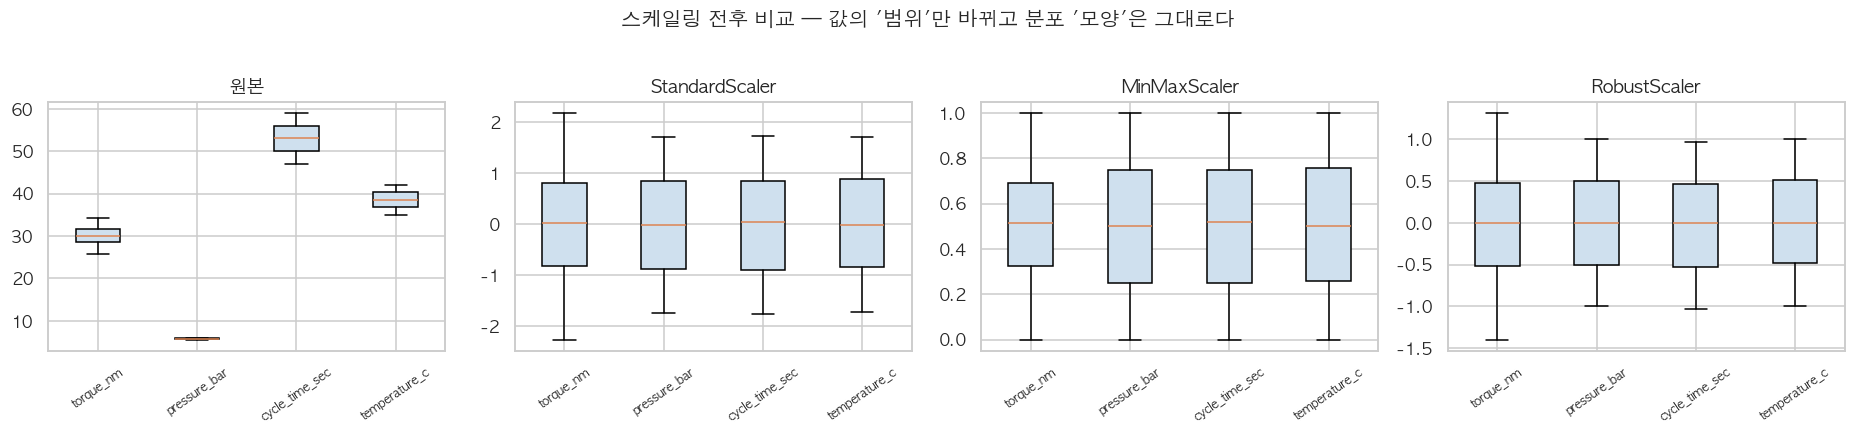

원본 범위 :
                  min    max
torque_nm      25.800 34.150
pressure_bar    5.600  6.000
cycle_time_sec 47.000 59.000
temperature_c  35.000 42.000


In [8]:
# =============================================================================
# [6-1] 스케일러 3종 비교 (개념 확인용 그림)
# =============================================================================
demo_cols = [c for c in NUM_A if df[c].notna().sum() > 50][:4]
demo = df[demo_cols].dropna()

scalers = {"원본": None, "StandardScaler": StandardScaler(),
           "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, sc) in zip(axes, scalers.items()):
    vals = demo.values if sc is None else sc.fit_transform(demo)
    ax.boxplot([vals[:, i] for i in range(vals.shape[1])],
               patch_artist=True, boxprops=dict(facecolor="#cfe0ee"))
    ax.set_xticks(range(1, len(demo_cols) + 1))
    ax.set_xticklabels(demo_cols)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=35, labelsize=8)
fig.suptitle("스케일링 전후 비교 — 값의 '범위'만 바뀌고 분포 '모양'은 그대로다", y=1.03)
plt.tight_layout()
plt.show()

print("원본 범위 :")
print(demo.agg(["min", "max"]).T.round(2).to_string())

In [9]:
# =============================================================================
# [6-2] 전처리 파이프라인 만들기
# =============================================================================
def make_preprocessor(cat_cols, num_cols, scaler="standard"):
    """수치형/범주형을 각각 다르게 처리하는 ColumnTransformer를 만든다."""
    sc = {"standard": StandardScaler(), "minmax": MinMaxScaler(),
          "robust": RobustScaler()}[scaler]

    # 수치형: 결측 → 중앙값 대치 → 스케일링
    num_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", sc),
    ])
    # 범주형: 결측 → 최빈값 대치 → 원핫인코딩
    cat_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ])


pre = make_preprocessor(CAT_A, NUM_A)
X_train_t = pre.fit_transform(X_train)      # fit은 학습 데이터에만!
X_test_t = pre.transform(X_test)            # 평가 데이터는 transform만
feat_names = pre.get_feature_names_out()

print(f"전처리 전 : {X_train.shape[1]}개 열")
print(f"전처리 후 : {X_train_t.shape[1]}개 열 (원핫인코딩으로 범주가 열로 펼쳐짐)")
print("\n[생성된 특성 이름 일부]")
print(list(feat_names[:12]), "...")

전처리 전 : 12개 열
전처리 후 : 23개 열 (원핫인코딩으로 범주가 열로 펼쳐짐)

[생성된 특성 이름 일부]
['num__torque_nm', 'num__pressure_bar', 'num__cycle_time_sec', 'num__temperature_c', 'num__vibration_mm_s', 'num__downtime_min', 'num__energy_kwh', 'cat__shift_야간', 'cat__shift_주간', 'cat__line_id_L1', 'cat__line_id_L2', 'cat__product_model_P1'] ...


---

## 7. 모델 3종 — 원리 이해하기

세 모델은 **"경계를 긋는 방식"** 이 다릅니다. 성능보다 **왜 다른 답을 내는지**를 이해하는
것이 중요합니다.

### ① 로지스틱 회귀 (Logistic Regression) — 선형 모델

이름에 '회귀'가 있지만 **분류 모델**입니다. 동작은 2단계입니다.

1. 각 변수에 **가중치(계수)** 를 곱해 전부 더한다
   → `z = w₁·토크 + w₂·온도 + w₃·진동 + ... + b`
2. 그 값을 **시그모이드 함수**에 넣어 0~1 사이 확률로 바꾼다
   → `P(양성) = 1 / (1 + e^(−z))`

**장점**: 계수를 보면 **어떤 변수가 어느 방향으로 얼마나 기여하는지** 바로 읽힙니다.
현업 설득력이 가장 높습니다.
**단점**: 변수들의 **직선적인 합**으로만 판단합니다. "야간 **그리고** M03일 때만 위험"
같은 조합(교호작용)은 사람이 변수를 만들어 넣어야 표현됩니다.

### ② 의사결정나무 (Decision Tree)

**스무고개**와 같습니다. "진동이 2.3보다 큰가?" → 예 → "온도가 85보다 큰가?" → ...
이렇게 질문을 이어가며 데이터를 나눕니다.

각 질문은 **불순도(impurity)** 가 가장 많이 줄어드는 기준으로 자동 선택됩니다.
불순도는 "한 그룹 안에 양성과 음성이 얼마나 섞여 있는가"입니다
(지니 계수 또는 엔트로피로 측정).

**장점**: 사람이 **그림으로 읽을 수 있습니다.** 현장 점검표로 바로 바꿀 수 있습니다.
**단점**: **과적합(overfitting)** 이 심합니다. 깊이를 제한하지 않으면 학습 데이터를
통째로 외워 버립니다.

> **과적합이란**: 학습 데이터의 **우연한 패턴까지 외우는 것**입니다.
> 시험 범위를 이해하지 않고 기출문제 답만 외운 학생과 같습니다.
> 학습 성능은 100%인데 새 데이터에서는 형편없습니다.
> → `max_depth`(깊이), `min_samples_leaf`(잎의 최소 표본 수)로 제한합니다.

### ③ 랜덤포레스트 (Random Forest) — 앙상블

나무 하나는 불안정합니다. 그래서 **나무 수백 그루를 만들어 다수결**로 판단합니다.
다만 모두 같은 나무면 의미가 없으므로 **두 가지 무작위성**을 넣습니다.

1. 나무마다 **데이터를 복원추출로 다시 뽑는다** (부트스트랩 = 배깅)
2. 각 분기에서 **변수의 일부만 후보로 본다**

이렇게 하면 나무마다 조금씩 다른 관점이 생기고, **다수결로 합치면 과적합이 줄어듭니다.**
"서로 다른 전문가 100명에게 물어보고 다수 의견을 따르는 것"과 같습니다.

**장점**: 대체로 성능이 가장 좋고, 결측·이상치에 비교적 강합니다.
**단점**: 나무 1그루처럼 그림으로 설명할 수 없습니다(그래서 3편에서 **특성중요도**를 봅니다).

### 불균형 데이터를 위한 `class_weight="balanced"`

양성이 4%뿐이면 모델은 "전부 음성"이라고 답하는 것이 손해가 적습니다.
`class_weight="balanced"` 는 **드문 쪽의 오류에 더 큰 벌점**을 줍니다
(양성 1건을 틀리는 비용을 음성보다 약 24배 크게 계산). 그 결과 Recall이 올라가고
Precision은 내려갑니다. **공짜 점심은 없습니다 — 둘은 맞바꾸는 관계입니다.**

In [10]:
# =============================================================================
# [7-1] 모델 3종 정의 (전처리 파이프라인과 묶어서)
# =============================================================================
SEED = 42       # 난수 고정 - 매번 같은 결과가 나오게 한다(재현성)

models = {
    "로지스틱회귀": Pipeline([
        ("pre", make_preprocessor(CAT_A, NUM_A)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                                   random_state=SEED)),
    ]),
    "의사결정나무": Pipeline([
        ("pre", make_preprocessor(CAT_A, NUM_A)),
        ("clf", DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                       class_weight="balanced", random_state=SEED)),
    ]),
    "랜덤포레스트": Pipeline([
        ("pre", make_preprocessor(CAT_A, NUM_A)),
        ("clf", RandomForestClassifier(n_estimators=300, max_depth=8,
                                       min_samples_leaf=5, class_weight="balanced",
                                       random_state=SEED, n_jobs=-1)),
    ]),
}

for name, m in models.items():
    m.fit(X_train, y_train)          # 학습: 전처리 fit + 모델 fit 이 한 번에
    print(f"{name} 학습 완료")

로지스틱회귀 학습 완료
의사결정나무 학습 완료


랜덤포레스트 학습 완료


---

## 8. 성능평가 — 혼동행렬부터 ROC-AUC까지

### 8-1. 혼동행렬(Confusion Matrix)

모든 분류 평가의 출발점입니다. 예측과 실제를 2×2 표로 적습니다.

| | 예측: 음성 | 예측: 양성 |
|---|---|---|
| **실제 음성** | TN (정상을 정상이라 함) | **FP (헛경보)** |
| **실제 양성** | **FN (놓침)** | TP (제대로 잡음) |

이 데이터에서의 의미:

| 칸 | 의미 | 현장에서 치르는 비용 |
|---|---|---|
| TP | 불합격(추가확인 대상) 를 제대로 찾아냄 | — (목표) |
| FN | 불합격(추가확인 대상) 인데 **놓침** | **사고·불량 유출·라인정지** |
| FP | 정상인데 **경보** | 불필요한 점검·검사 공수 |
| TN | 정상을 정상이라 판정 | — |

**FN과 FP의 비용은 절대 같지 않습니다.** 보통 FN(놓침)이 훨씬 비쌉니다.
이 비용 차이를 반영하는 것이 뒤에서 할 **임계값 조정**입니다.

### 8-2. 네 가지 지표

| 지표 | 계산식 | 질문 | 이 데이터에서 |
|---|---|---|---|
| **Accuracy** | (TP+TN)/전체 | 전체 중 몇 %를 맞혔나 | 불균형이라 **믿으면 안 됨** |
| **Recall(재현율)** | TP/(TP+FN) | **실제 양성 중 몇 %를 잡았나** | 놓치면 안 될 때 중요 |
| **Precision(정밀도)** | TP/(TP+FP) | **경보 중 몇 %가 진짜였나** | 헛경보 비용이 클 때 중요 |
| **F1** | 두 값의 조화평균 | 둘의 균형 | 하나로 비교할 때 |

**Recall과 Precision은 서로 맞바꾸는 관계(trade-off)** 입니다.
경보를 많이 울리면 Recall은 오르고 Precision은 떨어집니다.
**"어느 쪽이 중요한가"는 데이터가 아니라 현장이 정합니다.**

### 8-3. ROC 곡선과 AUC

모델은 사실 0/1이 아니라 **확률**(0~1)을 출력합니다. "몇 점 이상을 양성으로 볼까"가
**임계값(threshold)** 이고, 기본값은 0.5입니다.

**ROC 곡선**은 임계값을 0부터 1까지 모두 바꿔 가며
가로축에 **FPR**(헛경보율 = FP/실제음성), 세로축에 **TPR**(=Recall)을 찍은 그림입니다.

- 왼쪽 위 모서리에 가까울수록 좋다 (헛경보는 적고 탐지는 많다)
- 대각선 = 동전 던지기 수준

**AUC(Area Under Curve)** 는 이 곡선 아래 면적입니다.

| AUC | 해석 |
|---|---|
| 0.5 | 무작위 (쓸모없음) |
| 0.6~0.7 | 약함 |
| 0.7~0.8 | 쓸 만함 |
| 0.8~0.9 | 좋음 |
| 0.9 이상 | 매우 좋음 — **다만 데이터 누출을 먼저 의심** |

AUC의 직관적 의미: **"양성 하나와 음성 하나를 뽑았을 때, 모델이 양성에 더 높은
점수를 줄 확률"** 입니다. 임계값과 무관하게 모델의 **순위 매기기 능력**을 봅니다.

### 8-4. PR 곡선 — 불균형 데이터에서는 이쪽이 더 정직합니다

양성이 3~5%뿐이면 음성이 압도적으로 많아, FPR이 작게 나오기 쉽습니다.
그래서 **ROC-AUC가 좋아 보이는 착시**가 생깁니다.
**PR 곡선**(가로 Recall, 세로 Precision)과 **AP(평균 정밀도)** 를 함께 보세요.
PR 곡선의 기준선은 **양성 비율** 자체입니다(= 아무렇게나 찍었을 때의 Precision).

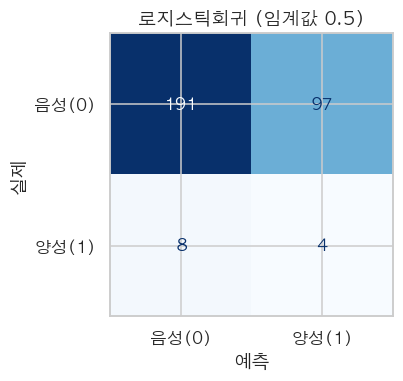

  TP(잡음) 4 / FN(놓침) 8 / FP(헛경보) 97 / TN 191
  Accuracy 0.650 | Recall 0.333 | Precision 0.040 | F1 0.071 | AUC 0.546


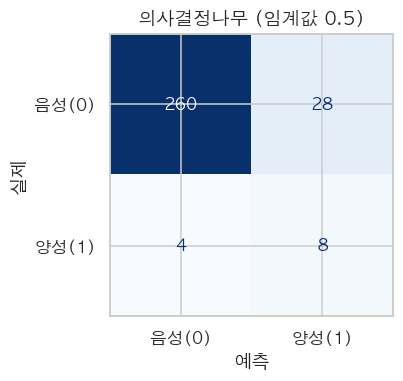

  TP(잡음) 8 / FN(놓침) 4 / FP(헛경보) 28 / TN 260
  Accuracy 0.893 | Recall 0.667 | Precision 0.222 | F1 0.333 | AUC 0.805


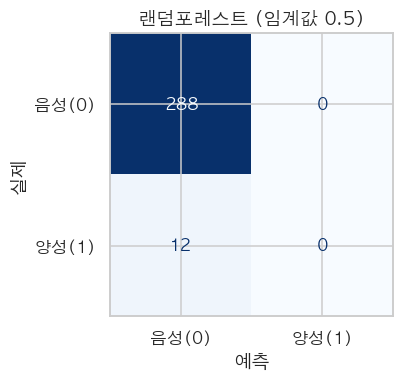

  TP(잡음) 0 / FN(놓침) 12 / FP(헛경보) 0 / TN 288
  Accuracy 0.960 | Recall 0.000 | Precision 0.000 | F1 0.000 | AUC 0.835


In [11]:
# =============================================================================
# [8-1] 평가 함수 - 지표 계산 + 혼동행렬 그림
# =============================================================================
def safe_auc(y_true, score):
    """양성 또는 음성이 하나도 없으면 AUC를 계산할 수 없으므로 NaN을 돌려준다."""
    return roc_auc_score(y_true, score) if y_true.nunique() == 2 else np.nan


def evaluate(model, name, X_te=None, y_te=None, threshold=0.5, show=True):
    """모델 성능을 계산하고(선택적으로) 혼동행렬을 그린다."""
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te

    proba = model.predict_proba(X_te)[:, 1]          # 양성일 확률
    pred = (proba >= threshold).astype(int)          # 임계값으로 0/1 결정

    cm = confusion_matrix(y_te, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    res = {
        "모델": name, "임계값": threshold,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred, zero_division=0),
        "F1": f1_score(y_te, pred, zero_division=0),
        "ROC_AUC": safe_auc(y_te, proba),
        "AP": average_precision_score(y_te, proba) if y_te.nunique() == 2 else np.nan,
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
        "경보건수": int(pred.sum()),
    }

    if show:
        fig, ax = plt.subplots(figsize=(4.2, 3.6))
        disp = ConfusionMatrixDisplay(cm, display_labels=["음성(0)", "양성(1)"])
        disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
        ax.set_title(f"{name} (임계값 {threshold})")
        ax.set_xlabel("예측")
        ax.set_ylabel("실제")
        plt.tight_layout()
        plt.show()
        print(f"  TP(잡음) {tp} / FN(놓침) {fn} / FP(헛경보) {fp} / TN {tn}")
        print(f"  Accuracy {res['Accuracy']:.3f} | Recall {res['Recall']:.3f} | "
              f"Precision {res['Precision']:.3f} | F1 {res['F1']:.3f} | "
              f"AUC {res['ROC_AUC']:.3f}")
    return res


results = [evaluate(m, n) for n, m in models.items()]

,임계값,Accuracy,Precision,Recall,F1,ROC_AUC,AP,TP,FN,FP,TN,경보건수
모델,,,,,,,,,,,,
기준선(전부 음성),-,0.960,0.000,0.000,0.000,0.500,0.040,0,12,0,288,0
로지스틱회귀,0.500,0.650,0.040,0.333,0.071,0.546,0.051,4,8,97,191,101
의사결정나무,0.500,0.893,0.222,0.667,0.333,0.805,0.151,8,4,28,260,36
랜덤포레스트,0.500,0.960,0.000,0.000,0.000,0.835,0.208,0,12,0,288,0


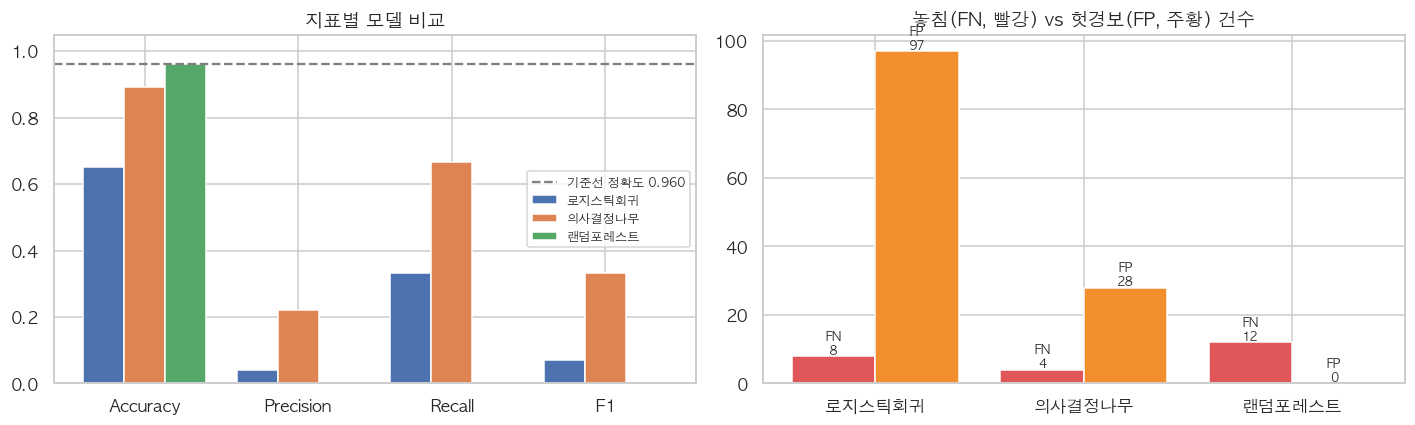

정확도만 보면 기준선(아무것도 안 하는 모델)이 높을 수 있다.
그러나 기준선은 양성을 '단 한 건도' 찾지 못한다(TP=0). 그래서 Recall을 함께 본다.


In [12]:
# =============================================================================
# [8-2] 모델 비교표 + '아무것도 안 하는 모델'(기준선)과의 비교
# =============================================================================
base_acc = 1 - y_test.mean()
baseline = {"모델": "기준선(전부 음성)", "임계값": "-", "Accuracy": base_acc,
            "Precision": 0.0, "Recall": 0.0, "F1": 0.0, "ROC_AUC": 0.5, "AP": y_test.mean(),
            "TP": 0, "FN": int(y_test.sum()), "FP": 0, "TN": int((y_test == 0).sum()),
            "경보건수": 0}

comp = pd.DataFrame([baseline] + results).set_index("모델")
display(comp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
metrics = ["Accuracy", "Precision", "Recall", "F1"]
idx = np.arange(len(metrics))
w = 0.8 / len(results)
for i, r in enumerate(results):
    axes[0].bar(idx + i * w, [r[m] for m in metrics], width=w, label=r["모델"])
axes[0].axhline(base_acc, color="gray", ls="--", label=f"기준선 정확도 {base_acc:.3f}")
axes[0].set_xticks(idx + 0.4 - w / 2)
axes[0].set_xticklabels(metrics)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("지표별 모델 비교")
axes[0].legend(fontsize=8)

for i, r in enumerate(results):
    axes[1].bar([i - 0.2, i + 0.2], [r["FN"], r["FP"]], width=0.4,
                color=["#e15759", "#f28e2b"])
    axes[1].text(i - 0.2, r["FN"], f"FN\n{r['FN']}", ha="center", va="bottom", fontsize=8)
    axes[1].text(i + 0.2, r["FP"], f"FP\n{r['FP']}", ha="center", va="bottom", fontsize=8)
axes[1].set_xticks(range(len(results)))
axes[1].set_xticklabels([r["모델"] for r in results])
axes[1].set_title("놓침(FN, 빨강) vs 헛경보(FP, 주황) 건수")
plt.tight_layout()
plt.show()

print("정확도만 보면 기준선(아무것도 안 하는 모델)이 높을 수 있다.")
print("그러나 기준선은 양성을 '단 한 건도' 찾지 못한다(TP=0). 그래서 Recall을 함께 본다.")

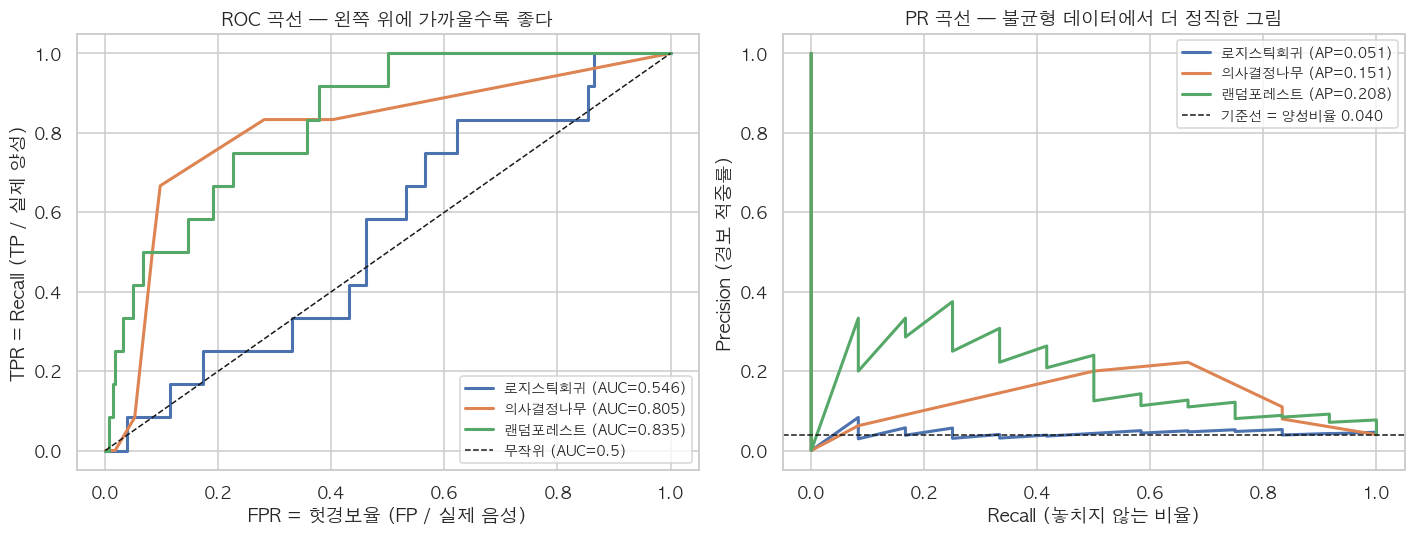

In [13]:
# =============================================================================
# [8-3] ROC 곡선과 PR 곡선
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = safe_auc(y_test, proba)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC={auc:.3f})")

    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    axes[1].plot(rec, prec, lw=2, label=f"{name} (AP={ap:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="무작위 (AUC=0.5)")
axes[0].set_xlabel("FPR = 헛경보율 (FP / 실제 음성)")
axes[0].set_ylabel("TPR = Recall (TP / 실제 양성)")
axes[0].set_title("ROC 곡선 — 왼쪽 위에 가까울수록 좋다")
axes[0].legend(fontsize=9)

axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1,
                label=f"기준선 = 양성비율 {y_test.mean():.3f}")
axes[1].set_xlabel("Recall (놓치지 않는 비율)")
axes[1].set_ylabel("Precision (경보 적중률)")
axes[1].set_title("PR 곡선 — 불균형 데이터에서 더 정직한 그림")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

### 이 데이터에서 나올 결과를 미리 읽어 두세요

- **AUC가 0.55~0.85 사이**로 모델마다 꽤 다르게 나옵니다. 신호가 약한 데이터이기 때문입니다.
  (불합격 48건, 그중 28건은 토크가 규격 안에 있습니다.)
- **랜덤포레스트가 기본 임계값 0.5에서 양성을 한 건도 예측하지 않을 수 있습니다(TP=0).**
  이것은 버그가 아닙니다. 양성이 4%뿐이라 **모든 기록의 양성 확률이 0.5를 넘지 못한** 것입니다.
  → 9절의 **임계값 조정**이 왜 필요한지 보여 주는 가장 좋은 사례입니다.
  확률 순위(AUC)는 괜찮은데 0.5라는 칸막이가 잘못된 것이므로, **모델을 바꿀 게 아니라
  임계값을 내려야** 합니다.
- 정확도는 셋 다 기준선(96%) 근처이거나 그보다 낮습니다. **정확도로 모델을 고르면 안 된다**는
  사실을 숫자로 확인하세요.

---

## 9. 임계값 조정 — 모델을 현장 조건에 맞추기

**모델을 바꾸지 않고도 성능 특성을 바꿀 수 있습니다.** 확률 임계값만 조정하면 됩니다.

| 임계값 | 경보 수 | Recall | Precision | 상황 |
|---|---|---|---|---|
| 높게 (0.7) | 적음 | 낮음 | 높음 | 점검 인력이 부족할 때 |
| 기본 (0.5) | 보통 | 보통 | 보통 | — |
| 낮게 (0.2) | 많음 | **높음** | 낮음 | 놓치면 큰일날 때 |

**현장 제약을 먼저 정하고 임계값을 고르는 것**이 올바른 순서입니다.

- "하루에 점검할 수 있는 설비가 2대뿐이다" → **상위 2건만 경보**(건수 제약)
- "불량 유출은 절대 안 된다" → **Recall 80% 이상**이 되는 임계값
- "헛경보가 많으면 현장이 경보를 무시한다" → Precision 하한선 설정

마지막 항목이 실무에서 특히 중요합니다. 헛경보가 반복되면 사람은 경보를 끕니다
(**경보 피로, alarm fatigue**). 기술적으로 완벽한 모델도 현장에서 무시되면 0점입니다.

비교 기준 모델: 의사결정나무


,임계값,경보건수,TP,FN,FP,Recall,Precision,F1
0,0.050,300,12,0,288,1.000,0.040,0.077
1,0.100,300,12,0,288,1.000,0.040,0.077
2,0.150,126,10,2,116,0.833,0.079,0.145
3,0.200,91,10,2,81,0.833,0.110,0.194
4,0.250,91,10,2,81,0.833,0.110,0.194
5,0.300,91,10,2,81,0.833,0.110,0.194
6,0.350,91,10,2,81,0.833,0.110,0.194
7,0.400,91,10,2,81,0.833,0.110,0.194
8,0.450,91,10,2,81,0.833,0.110,0.194
9,0.500,36,8,4,28,0.667,0.222,0.333


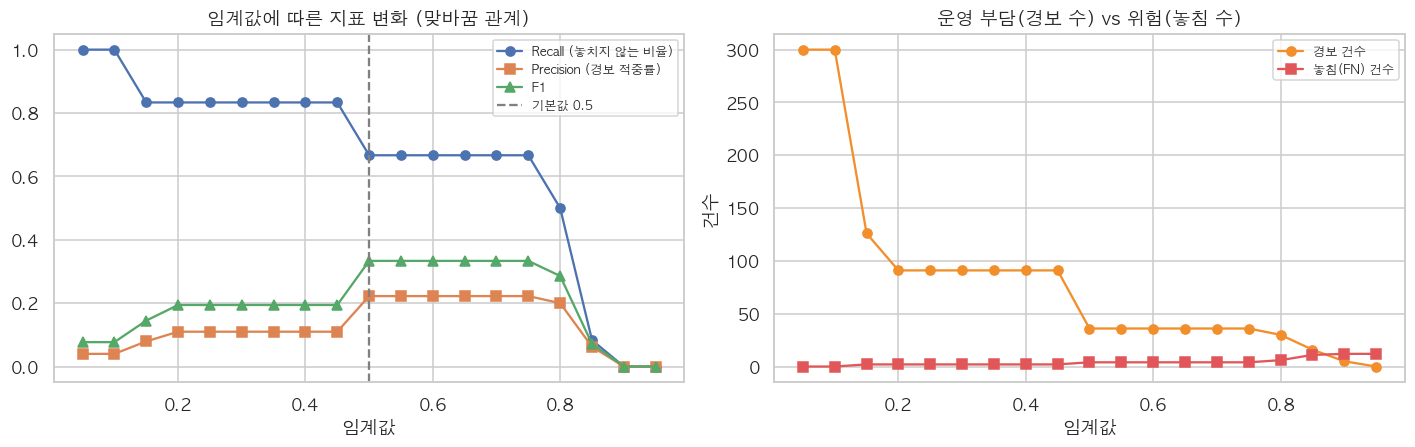

In [14]:
# =============================================================================
# [9-1] 임계값을 바꿔 가며 지표 변화 보기
# =============================================================================
best_model_name = max(results, key=lambda r: (r["F1"], r["Recall"]))["모델"]
best_model = models[best_model_name]
print("비교 기준 모델:", best_model_name)

proba = best_model.predict_proba(X_test)[:, 1]
rows = []
for th in np.arange(0.05, 0.96, 0.05):
    pred = (proba >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"임계값": round(th, 2), "경보건수": int(pred.sum()),
                 "TP": tp, "FN": fn, "FP": fp,
                 "Recall": recall_score(y_test, pred, zero_division=0),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "F1": f1_score(y_test, pred, zero_division=0)})
th_tbl = pd.DataFrame(rows)
display(th_tbl.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(th_tbl["임계값"], th_tbl["Recall"], "o-", label="Recall (놓치지 않는 비율)")
axes[0].plot(th_tbl["임계값"], th_tbl["Precision"], "s-", label="Precision (경보 적중률)")
axes[0].plot(th_tbl["임계값"], th_tbl["F1"], "^-", label="F1")
axes[0].axvline(0.5, color="gray", ls="--", label="기본값 0.5")
axes[0].set_xlabel("임계값")
axes[0].set_title("임계값에 따른 지표 변화 (맞바꿈 관계)")
axes[0].legend(fontsize=8)

axes[1].plot(th_tbl["임계값"], th_tbl["경보건수"], "o-", color="#f28e2b", label="경보 건수")
axes[1].plot(th_tbl["임계값"], th_tbl["FN"], "s-", color="#e15759", label="놓침(FN) 건수")
axes[1].set_xlabel("임계값")
axes[1].set_ylabel("건수")
axes[1].set_title("운영 부담(경보 수) vs 위험(놓침 수)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Recall 70% 이상을 만족하는 임계값 중 Precision이 가장 높은 값
임계값          0.200
경보건수        91.000
TP          10.000
FN           2.000
FP          81.000
Recall       0.833
Precision    0.110
F1           0.194

선택한 임계값: 0.2


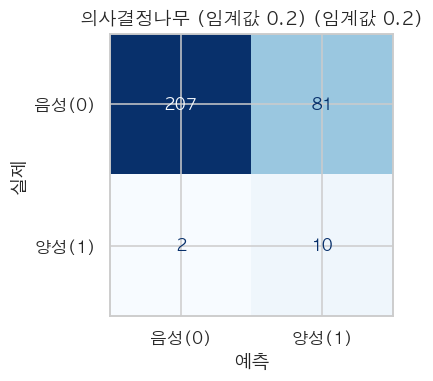

  TP(잡음) 10 / FN(놓침) 2 / FP(헛경보) 81 / TN 207
  Accuracy 0.723 | Recall 0.833 | Precision 0.110 | F1 0.194 | AUC 0.805

[참고] 상위 N건만 점검하는 운영 방식
  확률 상위   5건 점검 → 실제 양성 0건 포착 (전체 양성 12건 중 0%)
  확률 상위  10건 점검 → 실제 양성 1건 포착 (전체 양성 12건 중 8%)
  확률 상위  20건 점검 → 실제 양성 3건 포착 (전체 양성 12건 중 25%)
  확률 상위  30건 점검 → 실제 양성 6건 포착 (전체 양성 12건 중 50%)


In [15]:
# =============================================================================
# [9-2] 현장 제약으로 임계값 고르기 (예: Recall 70% 이상 중 Precision 최대)
# =============================================================================
TARGET_RECALL = 0.70

ok = th_tbl[th_tbl["Recall"] >= TARGET_RECALL]
if len(ok):
    chosen = ok.sort_values("Precision", ascending=False).iloc[0]
    print(f"Recall {TARGET_RECALL:.0%} 이상을 만족하는 임계값 중 Precision이 가장 높은 값")
    print(chosen.to_string())
    CHOSEN_TH = float(chosen["임계값"])
else:
    print(f"Recall {TARGET_RECALL:.0%} 를 만족하는 임계값이 없습니다. 가장 높은 Recall을 선택합니다.")
    chosen = th_tbl.sort_values("Recall", ascending=False).iloc[0]
    CHOSEN_TH = float(chosen["임계값"])

print(f"\n선택한 임계값: {CHOSEN_TH}")
final_res = evaluate(best_model, f"{best_model_name} (임계값 {CHOSEN_TH})",
                     threshold=CHOSEN_TH)

print("\n[참고] 상위 N건만 점검하는 운영 방식")
for n in [5, 10, 20, 30]:
    if n > len(proba):
        continue
    idx = np.argsort(-proba)[:n]                 # 확률이 높은 순서로 n건
    caught = int(y_test.iloc[idx].sum())
    print(f"  확률 상위 {n:>3d}건 점검 → 실제 양성 {caught}건 포착 "
          f"(전체 양성 {int(y_test.sum())}건 중 {caught/max(int(y_test.sum()),1)*100:.0f}%)")

---

## 10. 교차검증 — 한 번의 분리를 믿지 않기

train/test를 한 번만 나누면, **우연히 쉬운(또는 어려운) 데이터가 테스트에 몰릴 수**
있습니다. 특히 양성이 수십 건뿐인 데이터에서는 몇 건 차이로 지표가 크게 흔들립니다.

**K-겹 교차검증(K-Fold Cross Validation)** 은 데이터를 K조각으로 나눠,
각 조각을 한 번씩 테스트로 쓰고 나머지로 학습합니다(K번 반복).
**K개 성능의 평균과 표준편차**를 보면 "이 모델이 얼마나 안정적인가"를 알 수 있습니다.

- **StratifiedKFold**: 각 조각의 양성 비율을 똑같이 맞춥니다. 불균형 데이터의 기본.
- **TimeSeriesSplit**: 시간 순서를 지키며 나눕니다(과거로 학습 → 미래로 평가).
  최종 검증에는 이쪽이 현실적입니다.

**표준편차가 크면(예: ±0.1 이상) 그 모델은 믿기 어렵습니다.**

In [16]:
# =============================================================================
# [10-1] 5겹 교차검증 (StratifiedKFold)
# =============================================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
X_all = df[CAT_A + NUM_A]
y_all = df["target"]

cv_rows = []
for name, m in models.items():
    auc = cross_val_score(m, X_all, y_all, cv=cv, scoring="roc_auc", n_jobs=-1)
    rec = cross_val_score(m, X_all, y_all, cv=cv, scoring="recall", n_jobs=-1)
    f1 = cross_val_score(m, X_all, y_all, cv=cv, scoring="f1", n_jobs=-1)
    cv_rows.append({"모델": name,
                    "AUC 평균": auc.mean(), "AUC 표준편차": auc.std(),
                    "Recall 평균": rec.mean(), "Recall 표준편차": rec.std(),
                    "F1 평균": f1.mean(), "F1 표준편차": f1.std()})
    print(f"{name}: AUC {auc.mean():.3f} ± {auc.std():.3f}  "
          f"(각 폴드: {np.round(auc, 3)})")

cv_tbl = pd.DataFrame(cv_rows).set_index("모델")
display(cv_tbl.round(3))
print("표준편차가 크면 '운이 좋아서 나온 성능'일 수 있다 → 결론을 조심스럽게 쓴다.")

로지스틱회귀: AUC 0.651 ± 0.023  (각 폴드: [0.667 0.608 0.669 0.647 0.666])
의사결정나무: AUC 0.751 ± 0.057  (각 폴드: [0.861 0.707 0.738 0.706 0.744])


랜덤포레스트: AUC 0.833 ± 0.051  (각 폴드: [0.87  0.855 0.736 0.83  0.874])


,AUC 평균,AUC 표준편차,Recall 평균,Recall 표준편차,F1 평균,F1 표준편차
모델,,,,,,
로지스틱회귀,0.651,0.023,0.522,0.075,0.112,0.015
의사결정나무,0.751,0.057,0.727,0.093,0.177,0.066
랜덤포레스트,0.833,0.051,0.020,0.040,0.033,0.067


표준편차가 크면 '운이 좋아서 나온 성능'일 수 있다 → 결론을 조심스럽게 쓴다.


---

## 11. 시간순 분리로 '현실 성능' 확인하기

무작위 분리는 **과거와 미래를 섞습니다.** 7월 20일 데이터로 배워 7월 5일을 맞히는 것은
현장에서 일어날 수 없는 일입니다. 그래서 **시간순 분리**로 다시 평가합니다.

보통 성능이 떨어집니다. 이유는 두 가지입니다.

1. **분포 변화(drift)**: 시간이 지나면 설비 상태·생산 품목·계절이 바뀝니다.
2. **양성 사례 부족**: 뒤 기간에 양성이 몇 건 없으면 지표가 크게 흔들립니다.

**떨어진 성능이 진짜 성능입니다.** Blind Test(12~14회차)에서 겪게 될 상황이
바로 이것입니다. 지금 미리 확인해 두면 충격이 덜합니다.

In [17]:
# =============================================================================
# [11-1] 시간순 분리 재평가 (앞 75% 학습 → 뒤 25% 평가)
# =============================================================================
Xtr_t, Xte_t, ytr_t, yte_t = make_split(CAT_A, NUM_A, mode="time")
print(f"학습 {len(Xtr_t)}건 (양성 {int(ytr_t.sum())}건) / "
      f"평가 {len(Xte_t)}건 (양성 {int(yte_t.sum())}건)")

time_rows = []
for name, m in models.items():
    m2 = clone(m)                            # 같은 설정으로 새로 학습 (원본 모델은 그대로)
    m2.fit(Xtr_t, ytr_t)
    r = evaluate(m2, name, X_te=Xte_t, y_te=yte_t, show=False)
    r["분리"] = "시간순"
    time_rows.append(r)

rand_rows = [dict(r, 분리="무작위") for r in results]
both = pd.DataFrame(rand_rows + time_rows)[
    ["모델", "분리", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "TP", "FN", "FP"]]
display(both.set_index(["모델", "분리"]).round(3))

if yte_t.sum() < 5:
    print("※ 평가셋 양성이 5건 미만이라 시간순 결과는 참고용으로만 본다.")
print("무작위 분리보다 시간순 분리의 성능이 낮다면, 그것이 '현장에서 기대할 성능'이다.")

학습 900건 (양성 31건) / 평가 300건 (양성 17건)


,,Accuracy,Precision,Recall,F1,ROC_AUC,TP,FN,FP
모델,분리,,,,,,,,
로지스틱회귀,무작위,0.650,0.040,0.333,0.071,0.546,4,8,97
의사결정나무,무작위,0.893,0.222,0.667,0.333,0.805,8,4,28
랜덤포레스트,무작위,0.960,0.000,0.000,0.000,0.835,0,12,0
로지스틱회귀,시간순,0.680,0.101,0.588,0.172,0.732,10,7,89
의사결정나무,시간순,0.847,0.226,0.706,0.343,0.789,12,5,41
랜덤포레스트,시간순,0.943,0.000,0.000,0.000,0.858,0,17,0


무작위 분리보다 시간순 분리의 성능이 낮다면, 그것이 '현장에서 기대할 성능'이다.


---

## 13. 의사결정나무 들여다보기 — 현장 점검표로 바꾸기

머신러닝의 약점은 **"왜 그렇게 판단했는지 모른다"** 입니다. 그런데 의사결정나무는
**그림으로 전부 보여 줍니다.** 그래서 성능이 조금 낮아도 **현장 설득용**으로 매우 유용합니다.

그림 읽는 법:
- 각 상자의 첫 줄: **분기 조건** (조건이 참이면 왼쪽, 거짓이면 오른쪽)
- `samples`: 그 상자에 들어온 기록 수
- `value`: [음성 수, 양성 수] (가중치가 적용된 값)
- 색이 진할수록 한쪽 클래스로 치우친 상자

**잎(마지막 상자)에서 양성 비율이 높은 경로**를 따라 읽으면
그대로 **"현장 점검 규칙"** 이 됩니다.

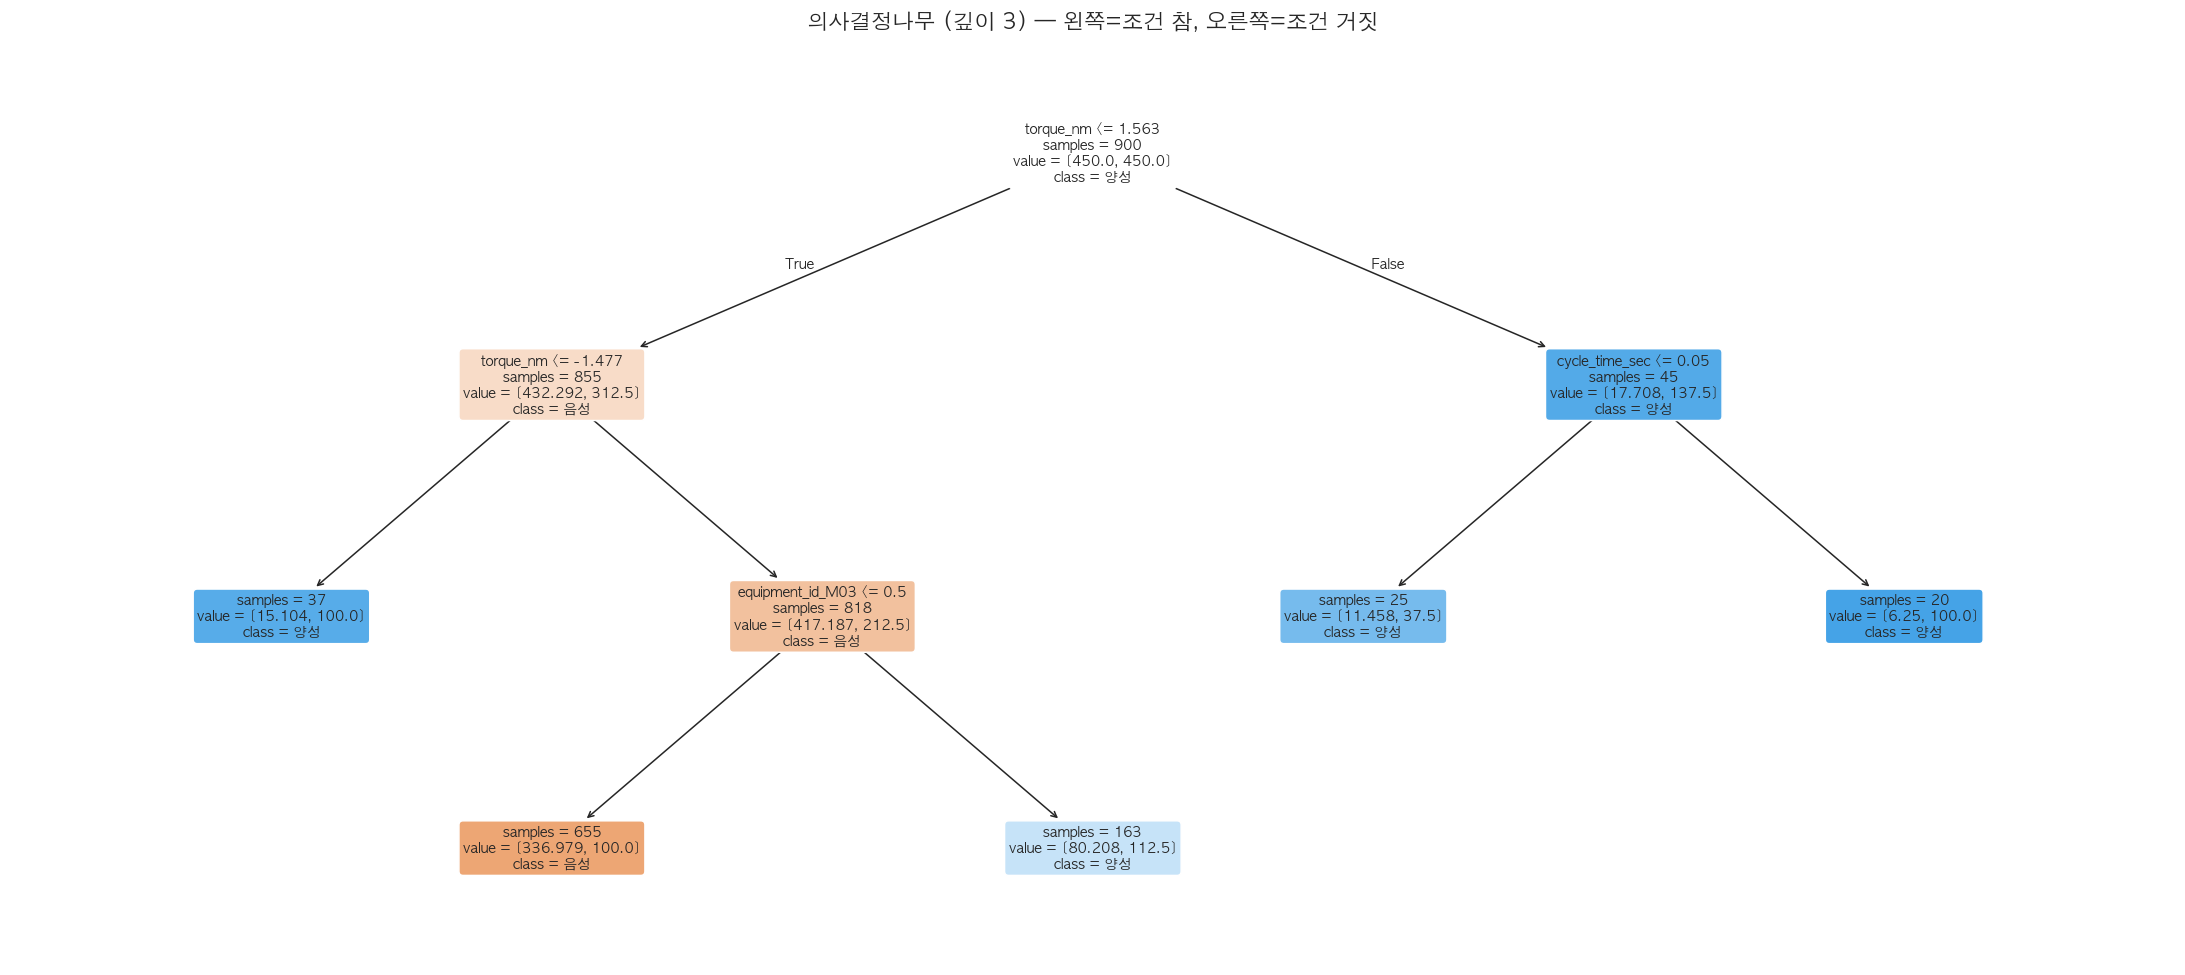

깊이 3 나무의 성능: Recall 0.667 / Precision 0.113 / AUC 0.725


In [18]:
# =============================================================================
# [13-1] 의사결정나무 그림 (깊이 3으로 줄여서 읽기 쉽게)
# =============================================================================
tree_pipe = Pipeline([
    ("pre", make_preprocessor(CAT_A, NUM_A)),
    ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=20,
                                   class_weight="balanced", random_state=SEED)),
])
tree_pipe.fit(X_train, y_train)

names = tree_pipe.named_steps["pre"].get_feature_names_out()
names = [n.replace("num__", "").replace("cat__", "") for n in names]

fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(tree_pipe.named_steps["clf"], feature_names=names,
          class_names=["음성", "양성"], filled=True, rounded=True,
          fontsize=9, ax=ax, proportion=False, impurity=False)
ax.set_title("의사결정나무 (깊이 3) — 왼쪽=조건 참, 오른쪽=조건 거짓", fontsize=14)
plt.tight_layout()
plt.show()

r_tree = evaluate(tree_pipe, "의사결정나무(깊이3)", show=False)
print(f"깊이 3 나무의 성능: Recall {r_tree['Recall']:.3f} / "
      f"Precision {r_tree['Precision']:.3f} / AUC {r_tree['ROC_AUC']:.3f}")

,깊이,학습 AUC,평가 AUC,차이
0,2,0.739,0.590,0.148
1,3,0.842,0.684,0.158
2,4,0.910,0.770,0.140
3,6,0.982,0.686,0.295
4,8,0.992,0.731,0.261
5,12,0.998,0.656,0.343
6,None,1.000,0.615,0.385


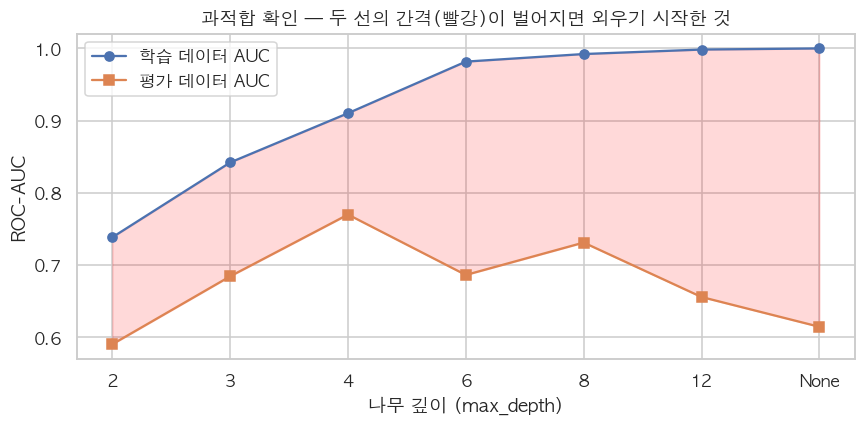

깊이를 키우면 학습 성능은 계속 오르지만 평가 성능은 어느 순간부터 떨어진다.
→ 그 지점 직전이 적절한 복잡도다. 이것이 '과적합과 일반화'의 핵심 그림이다.


In [19]:
# =============================================================================
# [13-2] 과적합 확인 - 나무 깊이를 바꿔 가며 학습/평가 성능 비교
# =============================================================================
depths = [2, 3, 4, 6, 8, 12, None]
rows = []
for d in depths:
    p = Pipeline([
        ("pre", make_preprocessor(CAT_A, NUM_A)),
        ("clf", DecisionTreeClassifier(max_depth=d, class_weight="balanced",
                                       random_state=SEED)),
    ])
    p.fit(X_train, y_train)
    tr = roc_auc_score(y_train, p.predict_proba(X_train)[:, 1])
    te = safe_auc(y_test, p.predict_proba(X_test)[:, 1])
    rows.append({"깊이": str(d), "학습 AUC": tr, "평가 AUC": te, "차이": tr - te})
ov = pd.DataFrame(rows)
display(ov.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ov["깊이"], ov["학습 AUC"], "o-", label="학습 데이터 AUC")
ax.plot(ov["깊이"], ov["평가 AUC"], "s-", label="평가 데이터 AUC")
ax.fill_between(ov["깊이"], ov["평가 AUC"], ov["학습 AUC"], alpha=0.15, color="red")
ax.set_xlabel("나무 깊이 (max_depth)")
ax.set_ylabel("ROC-AUC")
ax.set_title("과적합 확인 — 두 선의 간격(빨강)이 벌어지면 외우기 시작한 것")
ax.legend()
plt.tight_layout()
plt.show()

print("깊이를 키우면 학습 성능은 계속 오르지만 평가 성능은 어느 순간부터 떨어진다.")
print("→ 그 지점 직전이 적절한 복잡도다. 이것이 '과적합과 일반화'의 핵심 그림이다.")

---

## 14. 실패분석 — 놓친 사례(FN)와 헛경보(FP) 뜯어보기

**성능 숫자보다 중요한 것이 "어떤 사례를 왜 틀렸는가"** 입니다.
캡스톤 12~14회차의 실패분석이 바로 이 작업이며, 여기서 다음 세 가지를 얻습니다.

1. **모델의 한계** — 어떤 유형은 구조적으로 못 잡는다
2. **데이터의 한계** — 이 변수들로는 구분이 안 된다 → **센서 추가 제안**
3. **운영 보완책** — 모델이 못 잡는 영역은 사람이 점검하는 규칙으로 보완

놓친 사례(FN)들의 공통점을 찾아보세요. 그것이 다음 개선의 출발점입니다.

In [20]:
# =============================================================================
# [14-1] 놓친 사례(FN)와 헛경보(FP) 목록 뽑기
# =============================================================================
proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= CHOSEN_TH).astype(int)

err = X_test.copy()
err["실제"] = y_test.values
err["예측확률"] = proba.round(3)
err["예측"] = pred
err["판정"] = np.select(
    [(err["실제"] == 1) & (err["예측"] == 1),
     (err["실제"] == 1) & (err["예측"] == 0),
     (err["실제"] == 0) & (err["예측"] == 1)],
    ["TP(잡음)", "FN(놓침)", "FP(헛경보)"], default="TN")

print("[판정별 건수]")
print(err["판정"].value_counts().to_string())

fn = err[err["판정"] == "FN(놓침)"].sort_values("예측확률", ascending=False)
print(f"\n===== 놓친 사례 FN {len(fn)}건 (예측확률이 높은 순) =====")
display(fn.head(10))

fp = err[err["판정"] == "FP(헛경보)"].sort_values("예측확률", ascending=False)
print(f"\n===== 헛경보 FP {len(fp)}건 (상위 5건) =====")
display(fp.head(5))

[판정별 건수]
판정
FP(헛경보)    173
TN         115
TP(잡음)      12

===== 놓친 사례 FN 0건 (예측확률이 높은 순) =====


,shift,line_id,product_model,equipment_id,operator_group,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,실제,예측확률,예측,판정



===== 헛경보 FP 173건 (상위 5건) =====


,shift,line_id,product_model,equipment_id,operator_group,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,실제,예측확률,예측,판정
1129,야간,L1,P1,M03,G01,34.090,5.830,55.400,36.000,1.900,1,0.932,0,0.894,1,FP(헛경보)
1124,야간,L1,P1,M03,G05,33.410,5.610,52.800,36.800,2.040,1,0.965,0,0.894,1,FP(헛경보)
668,야간,L1,P1,M03,G03,33.450,5.950,54.000,39.500,1.320,0,0.940,0,0.894,1,FP(헛경보)
281,야간,L1,P1,M03,G03,33.670,5.710,51.100,41.500,2.470,1,0.954,0,0.894,1,FP(헛경보)
1092,야간,L1,P1,M03,G05,33.920,5.920,58.800,39.200,1.490,0,0.949,0,0.894,1,FP(헛경보)


In [21]:
# =============================================================================
# [14-2] 잡은 사례(TP) vs 놓친 사례(FN) 특성 비교
# =============================================================================
num_err = [c for c in NUM_A if c in err.columns]
tp_rows = err[err["판정"] == "TP(잡음)"]
fn_rows = err[err["판정"] == "FN(놓침)"]

if len(fn_rows) >= 2 and len(tp_rows) >= 2:
    cmp_err = pd.DataFrame({
        "TP(잡은 양성) 평균": tp_rows[num_err].mean(),
        "FN(놓친 양성) 평균": fn_rows[num_err].mean(),
        "전체 평균": err[num_err].mean(),
    })
    cmp_err["TP-FN 차이"] = cmp_err["TP(잡은 양성) 평균"] - cmp_err["FN(놓친 양성) 평균"]
    display(cmp_err.round(3))
    print("놓친 사례가 '평범한 값'을 가지고 있다면, 현재 변수로는 구분이 어렵다는 뜻이다.")
    print("→ 새로운 센서나 파생변수(3편)가 필요하다는 근거가 된다.")
else:
    print("놓친 사례(FN)가 너무 적어 비교가 어렵습니다. 임계값을 높여 다시 확인해 보세요.")

# 놓친 사례의 범주형 분포 (특정 조건에 몰려 있는가?)
for c in CAT_A[:3]:
    if c in err.columns and len(fn_rows):
        print(f"\n[{c}] 놓친 사례 분포:", dict(fn_rows[c].value_counts()))

놓친 사례(FN)가 너무 적어 비교가 어렵습니다. 임계값을 높여 다시 확인해 보세요.


---

## 15. 규칙 기반 판정과 비교 — Baseline v0 / v1

머신러닝을 배우기 전에, 현장에서 실제로 쓰는 방식은 **간단한 규칙**입니다.
1~2회차 미니 프로젝트의 핵심 활동이 바로 이 규칙을 만들고 개선하는 것이었습니다.

| 버전 | 규칙 | 의미 |
|---|---|---|
| **v0** | 체결토크 < 27 또는 > 33 | 공정 관리규격 하나만 사용 |
| **v1** | v0 **또는** (야간조 AND M03) | EDA에서 발견한 위험조건 추가 |

규칙의 장점은 분명합니다.
- **설명이 쉽다** (현장 교육 10분이면 충분)
- **바로 적용 가능** (시스템 개발 없이 작업표준에 반영)
- **고장나지 않는다** (모델 재학습·버전관리 불필요)

머신러닝이 규칙보다 나은 점은 **여러 변수의 조합을 동시에 고려**한다는 것입니다.
아래에서 **같은 기준(혼동행렬)으로 공정하게 비교**해 봅시다.
**규칙이 충분히 좋다면 규칙을 쓰는 것이 옳은 선택입니다.**

In [22]:
# =============================================================================
# [15-1] 규칙 v0 / v1 의 혼동행렬 (전체 1,200건 기준)
# =============================================================================
actual = (df["inspection_result"] == "불합격").astype(int)

rule_v0 = ((df["torque_nm"] < 27) | (df["torque_nm"] > 33)).astype(int)
rule_v1 = (rule_v0 | ((df["shift"] == "야간") & (df["equipment_id"] == "M03"))).astype(int)


def rule_report(name, rule):
    tn, fp, fn, tp = confusion_matrix(actual, rule, labels=[0, 1]).ravel()
    rec = tp / (tp + fn) if tp + fn else 0
    pre = tp / (tp + fp) if tp + fp else 0
    acc = (tp + tn) / len(actual)
    print(f"[{name}]  추가확인 {int(rule.sum()):>4d}건")
    print(f"   TP {tp:>3d} | FN {fn:>3d} | FP {fp:>4d} | TN {tn:>5d}")
    print(f"   Recall {rec*100:5.1f}% | Precision {pre*100:5.1f}% | Accuracy {acc*100:5.1f}%\n")
    return {"규칙": name, "추가확인": int(rule.sum()), "TP": tp, "FN": fn, "FP": fp,
            "TN": tn, "Recall": rec, "Precision": pre, "Accuracy": acc}


r0 = rule_report("v0: 토크 규격 이탈", rule_v0)
r1 = rule_report("v1: 토크 이탈 또는 야간M03", rule_v1)
display(pd.DataFrame([r0, r1]).set_index("규칙").round(3))

print("v0 → v1 변화:")
print(f"  놓침(FN)  {r0['FN']} → {r1['FN']} 건  ({r0['FN']-r1['FN']}건 감소)")
print(f"  헛경보(FP) {r0['FP']} → {r1['FP']} 건  ({r1['FP']-r0['FP']}건 증가)")
print("  → 불량 15건을 더 잡는 대가로 추가검사 45건이 늘었다. 이 맞바꿈을 현장이 받아들일까?")

[v0: 토크 규격 이탈]  추가확인  100건
   TP  20 | FN  28 | FP   80 | TN  1072
   Recall  41.7% | Precision  20.0% | Accuracy  91.0%

[v1: 토크 이탈 또는 야간M03]  추가확인  160건
   TP  35 | FN  13 | FP  125 | TN  1027
   Recall  72.9% | Precision  21.9% | Accuracy  88.5%



,추가확인,TP,FN,FP,TN,Recall,Precision,Accuracy
규칙,,,,,,,,
v0: 토크 규격 이탈,100,20,28,80,1072,0.417,0.200,0.910
v1: 토크 이탈 또는 야간M03,160,35,13,125,1027,0.729,0.219,0.885


v0 → v1 변화:
  놓침(FN)  28 → 13 건  (15건 감소)
  헛경보(FP) 80 → 125 건  (45건 증가)
  → 불량 15건을 더 잡는 대가로 추가검사 45건이 늘었다. 이 맞바꿈을 현장이 받아들일까?


In [23]:
# =============================================================================
# [15-2] 규칙 vs 머신러닝 (같은 평가 데이터에서 공정하게 비교)
# =============================================================================
test_idx = X_test.index
rule_v1_test = rule_v1.loc[test_idx]
tn, fp, fn, tp = confusion_matrix(y_test, rule_v1_test, labels=[0, 1]).ravel()

rule_row = {"모델": "규칙 v1", "Accuracy": (tp + tn) / len(y_test),
            "Precision": tp / (tp + fp) if tp + fp else 0,
            "Recall": tp / (tp + fn) if tp + fn else 0,
            "F1": 2 * tp / (2 * tp + fp + fn) if tp else 0,
            "ROC_AUC": np.nan, "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "경보건수": int(rule_v1_test.sum())}

final_cmp = pd.DataFrame([rule_row] + results + [final_res])
display(final_cmp.set_index("모델")[["Accuracy", "Precision", "Recall", "F1",
                                     "ROC_AUC", "TP", "FN", "FP", "경보건수"]].round(3))

print("비교할 때 주의할 점")
print(" 1) 규칙은 임계값 조정이 안 된다(고정). 모델은 임계값으로 운영점을 바꿀 수 있다.")
print(" 2) 규칙은 설명이 쉽고 유지보수가 필요 없다.")
print(" 3) 평가 데이터가 300건뿐이라 몇 건 차이로 지표가 흔들린다. 교차검증 결과를 함께 본다.")

,Accuracy,Precision,Recall,F1,ROC_AUC,TP,FN,FP,경보건수
모델,,,,,,,,,
규칙 v1,0.820,0.023,0.083,0.036,NaN,1,11,43,44
로지스틱회귀,0.650,0.040,0.333,0.071,0.546,4,8,97,101
의사결정나무,0.893,0.222,0.667,0.333,0.805,8,4,28,36
랜덤포레스트,0.960,0.000,0.000,0.000,0.835,0,12,0,0
의사결정나무 (임계값 0.2),0.723,0.110,0.833,0.194,0.805,10,2,81,91


비교할 때 주의할 점
 1) 규칙은 임계값 조정이 안 된다(고정). 모델은 임계값으로 운영점을 바꿀 수 있다.
 2) 규칙은 설명이 쉽고 유지보수가 필요 없다.
 3) 평가 데이터가 300건뿐이라 몇 건 차이로 지표가 흔들린다. 교차검증 결과를 함께 본다.


---

## 16. 2편 정리

### 오늘 한 일

1. 1편의 발견을 **`clean_data()` 함수**로 고정했다 (재현 가능한 전처리)
2. **판단 시점**을 기준으로 입력변수를 고르고, 결과변수를 제외했다 (누출 방지)
3. **Pipeline**으로 결측 대치 · 스케일링 · 원핫인코딩을 묶었다 (학습 데이터에서만 fit)
4. **로지스틱 회귀 · 의사결정나무 · 랜덤포레스트**를 학습하고 비교했다
5. **혼동행렬 · Recall · Precision · F1 · ROC-AUC · PR곡선**으로 평가했다
6. **임계값을 조정**해 현장 제약(점검 가능 건수, 목표 Recall)에 맞췄다
7. **놓친 사례(FN)** 를 뜯어보고 다음 개선 방향을 찾았다

### 꼭 기억할 5가지

| # | 원칙 |
|---|---|
| 1 | **정확도만 보지 않는다.** 불균형 데이터에서는 아무것도 안 해도 90%가 넘는다 |
| 2 | **FN과 FP의 비용은 다르다.** 어느 쪽이 비싼지는 현장이 정한다 |
| 3 | **성능이 너무 좋으면 누출을 의심한다.** AUC 0.99는 보통 사고다 |
| 4 | **임계값은 모델의 일부가 아니라 운영 정책이다.** 바꿔 가며 현장과 합의한다 |
| 5 | **시간순 분리 성능이 진짜 성능이다.** Blind Test에서 확인된다 |

### 3편으로 가져갈 질문

- 모델은 **어떤 변수를 보고** 그렇게 판단했는가? (계수 · 특성중요도)
- **변수를 더 잘 만들면** 성능이 오를까? (feature engineering)
- 변수를 **몇 개로 줄여도** 성능이 유지될까? (특성선택 · PCA)

---

## 연습문제 / 생각해 볼 질문

아래 문항은 정답을 맞히는 시험이 아니라, **발표자료에 쓸 문장을 만드는 연습**입니다.
코드를 조금씩 바꿔 보고, 결과를 한 문장으로 정리해 보세요.

1. `THRESHOLD` 값을 0.5 → 0.3 → 0.15 로 바꿔 보고, Recall / Precision / 추가검사 건수가 어떻게 움직이는지 표로 정리하세요. 품질팀이라면 어떤 값을 고르겠습니까?
2. `DecisionTreeClassifier(max_depth=...)` 를 2, 3, 6, None 으로 바꿔 보세요. 학습 데이터 성능과 테스트 성능의 차이(과적합)가 어떻게 변하나요?
3. `class_weight="balanced"` 를 빼고 로지스틱 회귀를 다시 학습해 보세요. 혼동행렬에서 무엇이 달라집니까?
4. 규칙 v1(토크 이탈 또는 야간M03)과 머신러닝 모델의 혼동행렬을 비교해, 어느 쪽을 현장에 먼저 적용할지와 그 이유를 쓰세요.
5. `final_disposition` 을 특성에 추가해 학습해 보세요. 성능이 거의 100%가 나올 것입니다. 이것이 왜 '성공'이 아니라 '데이터 누출'인지 설명하세요.

> **주의**: 숫자를 바꿔 실행할 때는 셀 하나만 다시 돌리지 말고,
> 바뀐 셀 **아래쪽을 모두** 다시 실행하세요. 위 셀의 결과를 아래 셀이 쓰기 때문입니다.

---

### 다음 노트북

**[01-3] 특성중요도 · Feature Engineering** 에서는
모델의 가중치와 특성중요도를 읽고, 도메인 지식으로 새 변수를 만들며,
특성선택과 PCA로 변수를 정리합니다.